In [17]:
import tensorflow as tf
import keras
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

## Load Dataset

In [18]:
DATASET_PATH = './Dataset-Vegan/'
classes = os.listdir(DATASET_PATH)
X, Y = [], []

for idx, clx in enumerate(classes):
    class_path = os.path.join(DATASET_PATH, clx)

    for raw_path in os.listdir(class_path):
        img_path = os.path.join(class_path, raw_path)

        img = keras.utils.load_img(img_path, color_mode="grayscale", target_size=(224, 224))
        img = keras.utils.img_to_array(img)

        X.append(img)
        Y.append(idx)

X = np.array(X)
Y = np.array(Y)

print("Dataset Loaded")


Dataset Loaded


## Preprocessing and Split

In [19]:
X = X.astype('float32') / 255
X_train, Xn, Y_train, Yn = train_test_split(X, Y, test_size=0.2, random_state=23)
X_val, X_test, Y_val, Y_test = train_test_split(Xn, Yn, test_size=0.5, random_state=23)

Y_train = keras.utils.to_categorical(Y_train, num_classes=len(classes))
Y_val = keras.utils.to_categorical(Y_val, num_classes=len(classes))
Y_test = keras.utils.to_categorical(Y_test, num_classes=len(classes))

## Framework

In [30]:
model = keras.Sequential([
    keras.layers.Conv2D(32, (3,3), activation="relu", input_shape=(224, 224, 1)),
    keras.layers.MaxPooling2D((2,2)),
    keras.layers.Conv2D(64, (3,3), activation="relu"),
    keras.layers.MaxPooling2D((2,2)),
    keras.layers.Conv2D(128, (3,3), activation="relu"),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation="relu"),
    # keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(len(classes), activation="softmax"),
])

model.summary()

c:\Users\mxlov\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 222, 222, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 346112)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │    44,302,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,395,652 (169.36 MB)

 Trainable params: 44,395,652 (169.36 MB)

 Non-trainable params: 0 (0.00 B)

## Training

In [31]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    X_train, Y_train, 
    epochs=10,
    batch_size=32,
    validation_data=(X_val, Y_val)
)

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 49s 959ms/step - accuracy: 0.5138 - loss: 1.1301 - val_accuracy: 0.5300 - val_loss: 0.9244
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 47s 940ms/step - accuracy: 0.7750 - loss: 0.6160 - val_accuracy: 0.7800 - val_loss: 0.5381
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 48s 953ms/step - accuracy: 0.8719 - loss: 0.3855 - val_accuracy: 0.8600 - val_loss: 0.4033
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 47s 931ms/step - accuracy: 0.9137 - loss: 0.2586 - val_accuracy: 0.8550 - val_loss: 0.3885
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 47s 941ms/step - accuracy: 0.9350 - loss: 0.2045 - val_accuracy: 0.8150 - val_loss: 0.4925
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 49s 972ms/step - accuracy: 0.9306 - loss: 0.1816 - val_accuracy: 0.7550 - val_loss: 0.6847
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 48s 962ms/step - accuracy: 0.9250 - loss: 0.1971 - val_accuracy: 0.8700 - val_loss: 0.3307
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 48s 961ms/step - accuracy: 0.9488 - loss: 0.1567 - val_accu

In [32]:
train_loss, train_acc = model.evaluate(X_train, Y_train)
print(f"Train Loss: {train_loss}")
print(f"Train Accuracy: {(train_acc*100):.2f}%")

50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 149ms/step - accuracy: 0.9663 - loss: 0.0979
Train Loss: 0.09789831191301346
Train Accuracy: 96.63%


In [33]:
test_loss, test_acc = model.evaluate(X_test, Y_test)
print(f"Test Loss: {test_loss}")
print(f"Test Accuracy: {test_acc*100:.2f}%")

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 128ms/step - accuracy: 0.8500 - loss: 0.5144
Test Loss: 0.5143833756446838
Test Accuracy: 85.00%


## Predict

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step


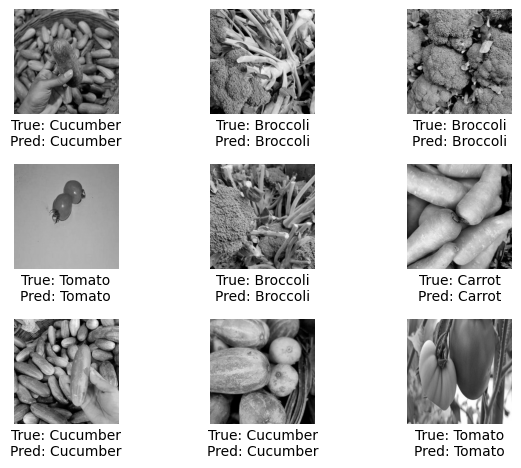

In [28]:
prediction = model.predict(X_test)
true = np.argmax(prediction, axis=1)
pred = np.argmax(Y_test, axis=1)

for i in range(9):
    plt.subplot(3,3, i+1)
    plt.imshow(X_test[i], cmap="gray")
    plt.axis(False)
    plt.text(0.5, -0.15, f"True: {classes[true[i]]}", ha="center", transform=plt.gca().transAxes)
    plt.text(0.5, -0.3,  f"Pred: {classes[pred[i]]}", ha="center", transform=plt.gca().transAxes)

plt.tight_layout()
plt.show()

## Ploting

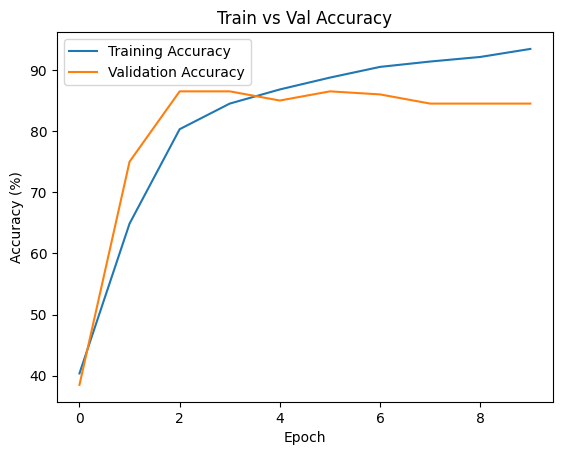

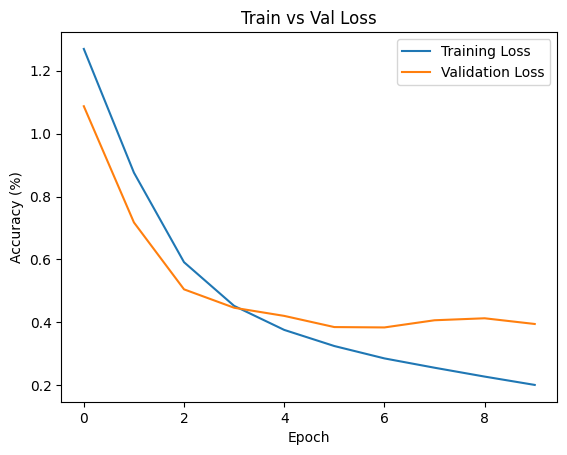

In [29]:
plt.title("Train vs Val Accuracy")
plt.plot([x * 100 for x in history.history['accuracy']], label="Training Accuracy")
plt.plot([x * 100 for x in history.history['val_accuracy']], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.show()

plt.title("Train vs Val Loss")
plt.plot(history.history['loss'], label="Training Loss")
plt.plot(history.history['val_loss'], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.show()